# 10 - Naive Bayes trên Mushroom

Mục tiêu: phân loại `class` (e = ăn được, p = độc) khi toàn bộ feature là categorical.

## 1. Load data và EDA ngắn

In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'mushrooms.csv'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
RANDOM_STATE = 42

df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Target distribution:')
print(df['class'].value_counts())
print('Unique values per column:')
print(df.nunique().sort_values())


Shape: (8124, 23)
Missing values: 0
Target distribution:
class
e    4208
p    3916
Name: count, dtype: int64
Unique values per column:
veil-type                    1
class                        2
gill-attachment              2
gill-spacing                 2
stalk-shape                  2
gill-size                    2
bruises                      2
ring-number                  3
stalk-surface-above-ring     4
veil-color                   4
cap-surface                  4
stalk-surface-below-ring     4
ring-type                    5
stalk-root                   5
cap-shape                    6
population                   6
habitat                      7
odor                         9
stalk-color-above-ring       9
stalk-color-below-ring       9
spore-print-color            9
cap-color                   10
gill-color                  12
dtype: int64


## 2. Tiền xử lý và lý do chọn model

`stalk-root` có ký tự `?`, giữ nguyên như một category riêng thay vì coi là missing. `veil-type` chỉ có một giá trị nên loại khỏi feature. Vì các feature đều categorical nên thứ tự số sau mã hóa không mang ý nghĩa liên tục, dùng `OrdinalEncoder` kết hợp `CategoricalNB`; `min_categories` được đặt theo toàn bộ dữ liệu để các category hợp lệ không gây lỗi khi dự đoán.

In [2]:
target = df['class']
X = df.drop(columns=['class', 'veil-type']).copy()
y = target.map({'e': 0, 'p': 1}).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
all_categories = [sorted(X[col].astype(str).unique()) for col in X.columns]
category_counts = [len(values) for values in all_categories]

model = Pipeline([
    ('encoder', OrdinalEncoder(
        categories=all_categories,
        handle_unknown='use_encoded_value',
        unknown_value=-1,
        dtype=np.float64,
    )),
    ('classifier', CategoricalNB(min_categories=category_counts)),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]


## 3. Đánh giá

accuracy     0.9458
precision    0.9901
recall       0.8966
f1           0.9410
roc_auc      0.9972
dtype: float64
              precision    recall  f1-score   support

 e (ăn được)       0.91      0.99      0.95       842
     p (độc)       0.99      0.90      0.94       783

    accuracy                           0.95      1625
   macro avg       0.95      0.94      0.95      1625
weighted avg       0.95      0.95      0.95      1625



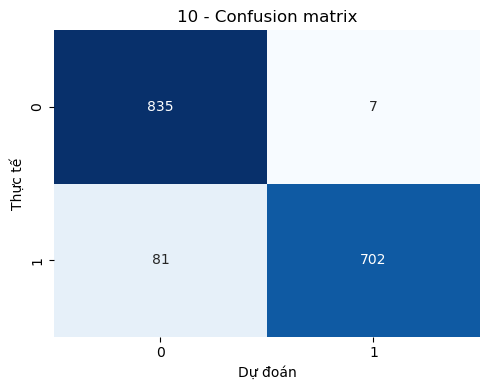

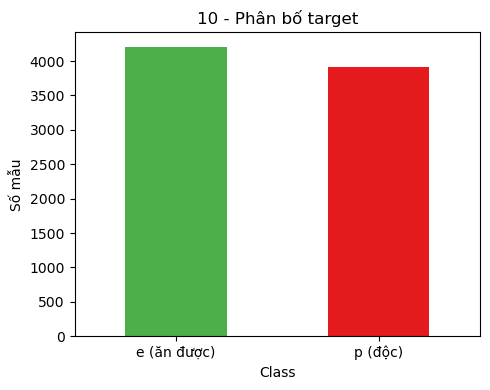

In [3]:
metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, zero_division=0),
    'recall': recall_score(y_test, y_pred, zero_division=0),
    'f1': f1_score(y_test, y_pred, zero_division=0),
    'roc_auc': roc_auc_score(y_test, y_prob),
}
print(pd.Series(metrics).round(4))
print(classification_report(y_test, y_pred, target_names=['e (ăn được)', 'p (độc)'], zero_division=0))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title('10 - Confusion matrix')
plt.tight_layout()
plt.savefig(FIGURES / '10_mushroom_confusion_matrix.png', dpi=150)
plt.show()

plt.figure(figsize=(5, 4))
y.value_counts().sort_index().rename(index={0:'e (ăn được)', 1:'p (độc)'}).plot(kind='bar', color=['#4daf4a', '#e41a1c'])
plt.xlabel('Class')
plt.ylabel('Số mẫu')
plt.title('10 - Phân bố target')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / '10_mushroom_target_distribution.png', dpi=150)
plt.show()


## 4. Nhận xét và bảng kết quả

Accuracy rất cao là bình thường với Mushroom và các thuộc tính nấm, mẫu mang thông tin mạnh để phân biệt nấm ăn được và nấm độc. Đây là một model categorical phù hợp, không cần StandardScaler. Các category được xác định từ toàn bộ feature để tránh lỗi category lạ ở test; việc fit encoder và classifier vẫn chỉ dùng tập train.

In [4]:
summary_path = FIGURES / 'results_summary.csv'
row = {
    'notebook': '10_mushroom_nb', 'dataset': 'mushrooms.csv', 'model': 'CategoricalNB',
    'best_params': str({'min_categories': category_counts}), **{k: float(v) for k, v in metrics.items()}
}
fieldnames = ['notebook', 'dataset', 'model', 'best_params', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']
existing = []
if summary_path.exists():
    with summary_path.open(newline='', encoding='utf-8') as f:
        existing = [r for r in csv.DictReader(f) if r.get('notebook') != row['notebook']]
with summary_path.open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(existing)
    writer.writerow(row)
print(pd.DataFrame([row]).round(4))


         notebook        dataset          model  \
0  10_mushroom_nb  mushrooms.csv  CategoricalNB   

                                         best_params  accuracy  precision  \
0  {'min_categories': [6, 4, 10, 2, 9, 2, 2, 2, 1...    0.9458     0.9901   

   recall     f1  roc_auc  
0  0.8966  0.941   0.9972  
